# Exercise 7: Polynomial Regression (Solution)
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

Use 'Housing price dataset_modified.csv'.

1) No data splitting

2) Predict 'MEDV' using both 'RM' and 'INDUS' with polynomial regression of order 2.

3) Calculate the MSE.

4) Plot a 3D graph of scattered data and regression plane using 'plotly.graph_objects' as in Practice 5.

# 1) Load data

In [ ]:
import pandas as pd

# Read the CSV file uploaded to the current Colab working directory
df = pd.read_csv("Housing price dataset_modified.csv")

# Have a look at the data shape and entries
# Showing the first 5 rows with .head()
# Remove .head() to show all the entries
print(df.shape)
df.head()

(506, 12)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,36.2


# 2) Histogram and scatter plot

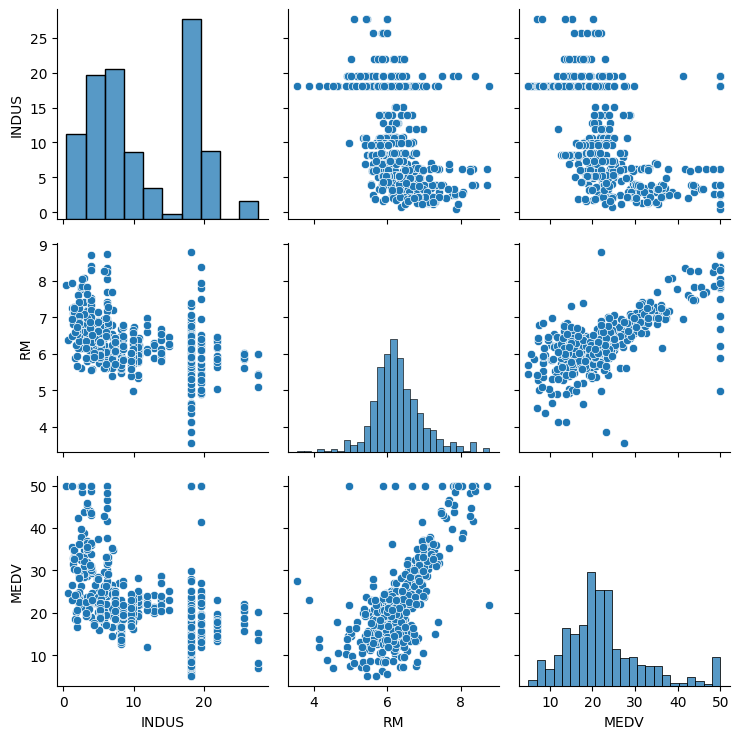

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pairplot to plot both histogram and scatter plot in one figure
cols = [
    "INDUS",
    "RM",
    "MEDV"
]

sns.pairplot(data=df, x_vars=cols, y_vars=cols)

plt.tight_layout()
plt.show()

# 3) Polynomial regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

X = df[['INDUS', 'RM']].values
y = df['MEDV'].values

reg = LinearRegression()

quadratic = PolynomialFeatures(degree=2)
X_quad = quadratic.fit_transform(X)

reg.fit(X_quad, y)

print(f"Coefficients: {reg.coef_}")
print(f"reg.intercept_: {reg.intercept_}")

# MSE
y_pred = reg.predict(X_quad)
mse = mean_squared_error(y, y_pred)
print(f"MSE: {mse:.3f}")

Coefficients: [ 0.00000000e+00  3.03085119e-01 -1.91475051e+01  1.15152962e-02
 -1.50442793e-01  2.21013870e+00]
reg.intercept_: 59.38753296130379
MSE: 32.111


In [ ]:
import numpy as np
import plotly.graph_objects as go

# Data points for visualization
x_axis = X[:, 0]   # first feature
y_axis = X[:, 1]   # second feature
z_axis = y         # target

# Create coordinate matrices for x and y
x_pred = np.linspace(x_axis.min(), x_axis.max(), 30)
y_pred = np.linspace(y_axis.min(), y_axis.max(), 30)

xx_pred, yy_pred = np.meshgrid(x_pred, y_pred)
model_viz = np.array([xx_pred.flatten(), yy_pred.flatten()]).T

# Predict z values on the grid
z_pred = reg.predict(quadratic.fit_transform(model_viz))

#z_pred = reg.predict(model_viz)
zz_pred = z_pred.reshape(xx_pred.shape)

# Create interactive 3D figure
fig = go.Figure()

# Original data points
fig.add_trace(go.Scatter3d(
    x=x_axis,
    y=y_axis,
    z=z_axis,
    mode='markers',
    marker=dict(
        size=4,
        color='black',
        opacity=0.5
    ),
    name='Data points'
))

# Regression surface
fig.add_trace(go.Surface(
    x=xx_pred,
    y=yy_pred,
    z=zz_pred,
    opacity=0.7,
    showscale=False,
    name='Regression surface'
))

# Layout
fig.update_layout(
    width=800,
    height=700,
    scene=dict(
        xaxis_title='INDUS',
        yaxis_title='RM',
        zaxis_title='MEDV'
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    title='3D Regression Plane'
)

fig.show()